In [1]:
%matplotlib inline
from transformers import AutoTokenizer
import torch 
import numpy as np
import pandas as pd
import pickle
import os
import re
import glob
import string
from torch.nn import functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from scipy import stats
from tqdm.notebook import tqdm
import sys
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
from sklearn.metrics import auc,precision_recall_curve,roc_auc_score,roc_curve
sys.path.append('..')
from utils import get_segmentation_indices,segmentation_to_word_list,model_to_path_dict
from statsmodels.tsa.stattools import acf

In [2]:
model_name = 'Llama3-8b-instruct'
save_dir = '../../generated'
model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
model_initial_char = model_to_path_dict[model_name]['initial_char']
tokenizer = AutoTokenizer.from_pretrained(model_to_path_dict[model_name]['hf_name'])

moth_output_dir = os.path.join(save_dir,model_save_dir_name,'moth_stories_output')
original_transcript_dir = '../../behavior_data/transcripts/moth_stories'
segmentation_dir = '../../behavior_data/segmentation'


stories = ['pieman','alternateithicatom','odetostepfather','souls','legacy','wheretheressmoke','adventuresinsayingyes','inamoment']
story_to_idx_mapping = {s:stories.index(s)+1 for s in stories}
plot_fontsize = 8
fig_save_dir = os.path.join(save_dir,model_save_dir_name,'surprisal_roc')
if not os.path.exists(fig_save_dir):
    os.makedirs(fig_save_dir)

## ROC

In [3]:
def auc_score_block_permutation(story_newline_prob,human_segmentation_bool,n_perm,block_size,pr_auc = False):
    '''
    pr_auc: if true, calculate AUC for precision vs. recall. If false, calculate the original AUC for FP vs. TP
    returns list of permuted auc values of length n_perm
    '''
    block_start_indices = np.arange(0,len(human_segmentation_bool),block_size).astype(int)
    
    # the last block might be smaller than the pre-determined block size 
    actual_block_size = np.repeat(block_size,len(block_start_indices))
    actual_block_size[-1] = len(human_segmentation_bool)-block_start_indices[-1]
    
    permuted_auc = np.zeros(n_perm)-1
    rng = np.random.default_rng(42)
    for i in range(n_perm):
        permuted_human_segmentation_bool = np.ones_like(human_segmentation_bool)*(-99)
        permuted_indices = rng.permutation(len(block_start_indices))
        permuted_block_start_indices = block_start_indices[permuted_indices]
        permuted_actual_block_size = actual_block_size[permuted_indices]
        assert permuted_block_start_indices.shape == block_start_indices.shape
        assert permuted_actual_block_size.shape == actual_block_size.shape
        #print(len(permuted_block_start_indices))
        filled_ind = 0 # start index of this block
        for chunk_ind,permuted_start_ind in enumerate(permuted_block_start_indices):
            this_block_size = permuted_actual_block_size[chunk_ind] # size of the chunk after permutation
            permuted_human_segmentation_bool[filled_ind:filled_ind+this_block_size]=human_segmentation_bool[permuted_start_ind:permuted_start_ind+this_block_size]
            filled_ind = filled_ind+permuted_actual_block_size[chunk_ind] # update for next block 
        assert sum(permuted_human_segmentation_bool==-99)==0,'all indices in permuted_human_segmentation_bool must be filled'
        
        if pr_auc: # auc of precision vs. recall 
            precision, recall, pr_thresholds = precision_recall_curve(y_true = permuted_human_segmentation_bool,probas_pred=story_newline_prob)
            this_auc = auc(recall, precision)
        else: # original auc 
            this_auc = roc_auc_score(y_true = permuted_human_segmentation_bool,y_score = story_newline_prob)
        permuted_auc[i]=this_auc
    assert sum((permuted_auc)==-1)==0,'no entries of permuted_auc should be -1'
    return permuted_auc

### surprisal

In [4]:
num_events = []
for story in stories:
    consensus_path = os.path.join(segmentation_dir,story,'%s_consensus.txt'%story)
    with open(consensus_path,'r') as f:
        consensus_txt = f.read()
    consensus_txt = consensus_txt.split('\n')
    num_events.append(len(consensus_txt))
mean_num_events = np.mean(num_events)
print('Mean number of events across stories: %.2f'%mean_num_events)

Mean number of events across stories: 19.25


In [5]:
smooth_sds = [0,10,30,50]
n_perm = 1000
block_size = np.round(mean_num_events).astype(int) # block size for permutation test
story_roc_dict = {}
story_perm_auc_dict = {}
story_auc_dict = {}
for story in tqdm(stories):
    with open(os.path.join(moth_output_dir,story,'cross_entropy.pkl'),'rb') as f:
        original_ce = pickle.load(f)
    # tokenized txt 
    with open(os.path.join(moth_output_dir,story,'tokenized_txt.pkl'),'rb') as f:
        tokenized_txt = pickle.load(f)
    story_tokens = torch.load(os.path.join(moth_output_dir,story,'tokens.pkl'),map_location=torch.device('cpu'))
    story_tokens = story_tokens[0,1:].cpu().detach()
    consensus_path = os.path.join(segmentation_dir,story,'%s_consensus.txt'%story)
    with open(consensus_path,'r') as f:
        consensus_txt = f.read()
    consensus_txt = consensus_txt.split('\n')
    with open(os.path.join(original_transcript_dir,'%s.txt'%story),'r') as f:
        original_txt = f.read()
    consensus_wordlist = segmentation_to_word_list(consensus_txt)
    # humans segment after each of these tokens (ie these indices are still in the current event)
    segmentation_indices_in_tokens = get_segmentation_indices(tokenized_txt,consensus_wordlist,original_txt,initial_char='Ġ')
    segmentation_indices_in_tokens = segmentation_indices_in_tokens[:-1] # get rid of the end of story
    
    human_segment_bool = torch.zeros(original_ce.shape)
    human_segment_bool[segmentation_indices_in_tokens] = 1
    human_segment_bool = human_segment_bool.numpy()

    story_roc_dict[story] = {}
    story_perm_auc_dict[story] = {}
    story_auc_dict[story] = {}
    for smooth_sd in smooth_sds:
        if smooth_sd!=0:
            smoothed_ce = gaussian_filter1d(original_ce,sigma = smooth_sd)
            fpr, tpr, thresholds = roc_curve(human_segment_bool, smoothed_ce)
            auc = roc_auc_score(human_segment_bool, smoothed_ce)
            perm_auc = auc_score_block_permutation(smoothed_ce,human_segment_bool,n_perm,block_size,pr_auc = False)
            story_roc_dict[story][smooth_sd] = {'fpr':fpr,'tpr':tpr}
            story_perm_auc_dict[story][smooth_sd] =perm_auc
            story_auc_dict[story][smooth_sd] = auc
        else:
            fpr, tpr, thresholds = roc_curve(human_segment_bool, original_ce.numpy())
            auc = roc_auc_score(human_segment_bool, original_ce)
            perm_auc = auc_score_block_permutation(original_ce.numpy(),human_segment_bool,n_perm,block_size,pr_auc = False)
            story_roc_dict[story][smooth_sd] = {'fpr':fpr,'tpr':tpr}
            story_perm_auc_dict[story][smooth_sd] =perm_auc
            story_auc_dict[story][smooth_sd] = auc
    #print(story,np.sum(auc>perm_auc)/n_perm)

  0%|          | 0/8 [00:00<?, ?it/s]

In [6]:
for story in tqdm(stories):
    with open(os.path.join(moth_output_dir,story,'cross_entropy.pkl'),'rb') as f:
        original_ce = pickle.load(f)
    # tokenized txt 
    with open(os.path.join(moth_output_dir,story,'tokenized_txt.pkl'),'rb') as f:
        tokenized_txt = pickle.load(f)
    story_tokens = torch.load(os.path.join(moth_output_dir,story,'tokens.pkl'),map_location=torch.device('cpu'))
    story_tokens = story_tokens[0,1:].cpu().detach()
    consensus_path = os.path.join(segmentation_dir,story,'%s_consensus.txt'%story)
    with open(consensus_path,'r') as f:
        consensus_txt = f.read()
    consensus_txt = consensus_txt.split('\n')
    with open(os.path.join(original_transcript_dir,'%s.txt'%story),'r') as f:
        original_txt = f.read()
    consensus_wordlist = segmentation_to_word_list(consensus_txt)
    # humans segment after each of these tokens (ie these indices are still in the current event)
    segmentation_indices_in_tokens = get_segmentation_indices(tokenized_txt,consensus_wordlist,original_txt,initial_char='Ġ')
    break

  0%|          | 0/8 [00:00<?, ?it/s]

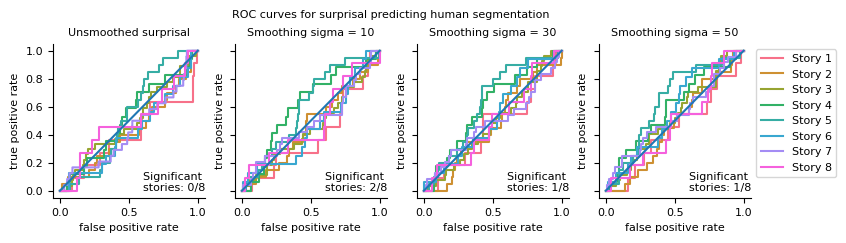

In [7]:
colors = sns.husl_palette(len(stories))
fig,axes = plt.subplots(figsize = (9,2),nrows = 1,ncols = 4,sharey = True)
for smooth_sd,ax in zip(smooth_sds,axes.flatten()):
    sig_count = 0
    for i,story in enumerate(stories):
        fpr = story_roc_dict[story][smooth_sd]['fpr']
        tpr = story_roc_dict[story][smooth_sd]['tpr']
        ax.plot(fpr,tpr,color = colors[i],label = story)

        story_perm_auc =story_perm_auc_dict[story][smooth_sd]
        story_auc = story_auc_dict[story][smooth_sd]
        pval = np.sum(story_perm_auc>story_auc)/n_perm
        if pval < 0.05:
            sig_count+=1
    xx = np.linspace(0,1,100)
    ax.plot(xx,xx)
    ax.text(0.8,0.1,'Significant \nstories: %s/%s'%(sig_count,len(stories)),ha = 'center',va = 'center',transform = ax.transAxes,fontsize = plot_fontsize)
    ax.set_xlabel('false positive rate',fontsize = plot_fontsize)
    ax.set_ylabel('true positive rate',fontsize = plot_fontsize)
    ax.tick_params(axis='both', labelsize=plot_fontsize)
    if smooth_sd!=0:
        ax.set_title('Smoothing sigma = %s'%smooth_sd,fontsize = plot_fontsize)
    else:
        ax.set_title('Unsmoothed surprisal',fontsize = plot_fontsize)
    if ax == axes.flatten()[-1]:
        handles, labels = ax.get_legend_handles_labels()
        mapped_labels = ['Story %s' % story_to_idx_mapping[label] for label in labels]
        ax.legend(handles, mapped_labels, bbox_to_anchor=(1, 1),fontsize = plot_fontsize)
        #ax.legend(bbox_to_anchor = (1,1))
#fig.legend(bbox_to_anchor = (1,1))
fig.suptitle('ROC curves for surprisal predicting human segmentation',fontsize = plot_fontsize,y = 1.05)
sns.despine()
fig.savefig(os.path.join(fig_save_dir,'surprisal_ROC_segmentation.svg'),transparent = True)

## Thresholding surprisal to obtain boundaries, and test Wasserstein distance against random baseline 

In [31]:
from scipy.ndimage import gaussian_filter1d
from scipy.stats import wasserstein_distance

In [5]:
def get_human_segment_bool(consensus_txt,tokenized_txt,original_txt,original_ce):
    consensus_wordlist = segmentation_to_word_list(consensus_txt)
    # humans segment after each of these tokens (ie these indices are still in the current event)
    segmentation_indices_in_tokens = get_segmentation_indices(tokenized_txt,consensus_wordlist,original_txt,initial_char='Ġ')
    segmentation_indices_in_tokens = segmentation_indices_in_tokens[:-1] # get rid of the end of story
    human_segment_bool = torch.zeros(original_ce.shape)
    human_segment_bool[segmentation_indices_in_tokens] = 1
    human_segment_bool = human_segment_bool.numpy().astype(float)
    return human_segment_bool
def get_model_segment_bool(original_ce,multiplier):
    mean_ce = torch.mean(original_ce)
    sd_ce = torch.std(original_ce)
    thresh = mean_ce+sd_ce * multiplier
    surprisal_above_thresh = original_ce>thresh
    surprisal_above_thresh = surprisal_above_thresh.numpy().astype(float)
    return surprisal_above_thresh

In [6]:
def random_boundaries(human_segment_bool,human_segment_bool_smoothed,smooth_sd,num_boundaries,N):
    '''randomly pick the same number of boundaries as human boundaries and calculate the wasserstein distance to the 
    discrete and smoothed boundary time courses'''
    #num_boundaries = np.sum(human_segment_bool>0)
    rng = np.random.default_rng(42)
    dist_to_random_discrete = []
    dist_to_random_smoothed = []
    for i in range(N):
        random_boundaries = np.zeros(human_segment_bool.shape)
        boundary_indices = rng.choice(len(human_segment_bool),num_boundaries,replace = False) # choose num_boundaries indices
        random_boundaries[boundary_indices] = 1
        random_boundaries_smoothed = gaussian_filter1d(random_boundaries,smooth_sd)
        indices = np.arange(len(human_segment_bool))
        dist_discrete = wasserstein_distance(u_values = indices, v_values = indices,u_weights = human_segment_bool,v_weights = random_boundaries)
        dist_smoothed = wasserstein_distance(u_values = indices, v_values = indices,u_weights = human_segment_bool_smoothed,v_weights = random_boundaries_smoothed)
        dist_to_random_discrete.append(dist_discrete)
        dist_to_random_smoothed.append(dist_smoothed)
        
    # plt.figure(figsize=(10,1))
    # plt.plot(random_boundaries,label ='random discrete ex')
    # plt.plot(random_boundaries_smoothed,label ='random smoothed ex')
    # plt.plot(human_segment_bool,label='human discrete')
    # plt.plot(human_segment_bool_smoothed,label='human discrete')
    # plt.legend()
    return dist_to_random_discrete,dist_to_random_smoothed
        

In [34]:
N = 5000
multiplier = 3.1
smooth_sd = 5
all_stories_dist_smoothed = {}
all_stories_dist_to_random_smoothed ={}
for story in stories:
    with open(os.path.join(moth_output_dir,story,'cross_entropy.pkl'),'rb') as f:
        original_ce = pickle.load(f)
    # tokenized txt 
    with open(os.path.join(moth_output_dir,story,'tokenized_txt.pkl'),'rb') as f:
        tokenized_txt = pickle.load(f)
    story_tokens = torch.load(os.path.join(moth_output_dir,story,'tokens.pkl'),map_location=torch.device('cpu'))
    story_tokens = story_tokens[0,1:].cpu().detach()
    consensus_path = os.path.join(segmentation_dir,story,'%s_consensus.txt'%story)
    with open(consensus_path,'r') as f:
        consensus_txt = f.read()
    consensus_txt = consensus_txt.split('\n')
    with open(os.path.join(original_transcript_dir,'%s.txt'%story),'r') as f:
        original_txt = f.read()
    
    human_segment_bool = get_human_segment_bool(consensus_txt,tokenized_txt,original_txt,original_ce)
    surprisal_above_thresh = get_model_segment_bool(original_ce,multiplier)

    human_segment_bool_smoothed = gaussian_filter1d(human_segment_bool,smooth_sd)
    surprisal_segment_smoothed = gaussian_filter1d(surprisal_above_thresh,smooth_sd)
    indices = np.arange(len(human_segment_bool))
    dist_discrete = wasserstein_distance(u_values = indices, v_values = indices,u_weights = human_segment_bool,v_weights = surprisal_above_thresh)
    dist_smoothed = wasserstein_distance(u_values = indices, v_values = indices,u_weights = human_segment_bool_smoothed,v_weights = surprisal_segment_smoothed)
    dist_to_random_discrete,dist_to_random_smoothed = random_boundaries(human_segment_bool,human_segment_bool_smoothed,smooth_sd,np.sum(surprisal_above_thresh>0),N)

    print(story)
    print('Num human segmentation: %d, num surprisal segmentation: %d'%(np.sum(human_segment_bool>0),np.sum(surprisal_above_thresh>0)))

    print('discrete, % random boundary distance > actual:',np.sum(dist_to_random_discrete>dist_discrete)/N)
    print('smoothed, % random boundary distance > actual:',np.sum(dist_to_random_smoothed>dist_smoothed)/N)

    print()
    # plt.figure(figsize = (10,1))
    # #plt.plot(surprisal_above_thresh)
    # plt.plot(surprisal_segment_smoothed,label = 'surprisal')
    # plt.plot(human_segment_bool_smoothed,label = 'human')
    # #plt.plot(human_segment_bool)
    # plt.legend()
    # plt.title(story)
    all_stories_dist_smoothed[story] = dist_smoothed
    all_stories_dist_to_random_smoothed[story] = dist_to_random_smoothed
    #print(torch.sum(original_ce>thresh),len(segmentation_indices_in_tokens))

pieman
Num human segmentation: 11, num surprisal segmentation: 11
discrete, % random boundary distance > actual: 0.5478
smoothed, % random boundary distance > actual: 0.548

alternateithicatom
Num human segmentation: 20, num surprisal segmentation: 22
discrete, % random boundary distance > actual: 0.1312
smoothed, % random boundary distance > actual: 0.1312

odetostepfather
Num human segmentation: 27, num surprisal segmentation: 29
discrete, % random boundary distance > actual: 0.9046
smoothed, % random boundary distance > actual: 0.9046

souls
Num human segmentation: 17, num surprisal segmentation: 23
discrete, % random boundary distance > actual: 0.512
smoothed, % random boundary distance > actual: 0.5124

legacy
Num human segmentation: 20, num surprisal segmentation: 22
discrete, % random boundary distance > actual: 0.9254
smoothed, % random boundary distance > actual: 0.9258

wheretheressmoke
Num human segmentation: 16, num surprisal segmentation: 15
discrete, % random boundary dis

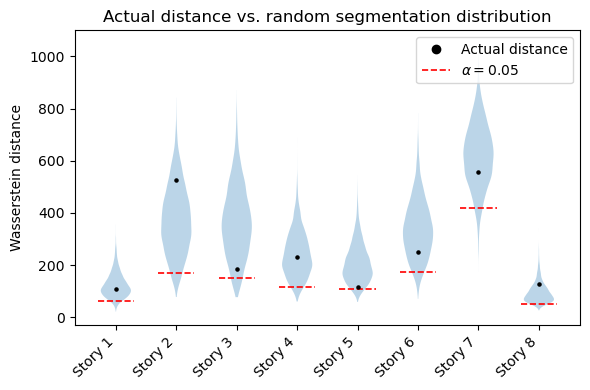

In [35]:
from matplotlib.lines import Line2D
# Collect random samples in story order
data = [all_stories_dist_to_random_smoothed[s] for s in stories]
actual = [all_stories_dist_smoothed[s] for s in stories]
chance_levels = [np.percentile(all_stories_dist_to_random_smoothed[s], 5) 
                 for s in stories]

fig, ax = plt.subplots(figsize=(6, 4))

# Violin plot (vertical)
vp = ax.violinplot(data, showmeans=False, showextrema=False, showmedians=False)

# Plot actual values
ax.scatter(range(1, len(stories)+1), actual, zorder=3,s = 5,color = 'black')

# Chance levels (bottom 5%) in red dashed line
for i, cl in enumerate(chance_levels, start=1):
    ax.hlines(cl, i - 0.3, i + 0.3, colors='red', linestyles='--', linewidth=1.2)

legend_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markeredgecolor='black', markersize=6, label='Actual distance'),
    Line2D([0], [0], color='red', linestyle='--', linewidth=1.2, label=r'$\alpha = 0.05$'),
]
ax.legend(handles=legend_handles, loc='upper right', frameon=True)

# X-axis labels
ax.set_xticks(range(1, len(stories)+1))
ax.set_xticklabels(['Story '+str(story_to_idx_mapping[story]) for story in stories], rotation=45, ha='right')

ax.set_ylabel("Wasserstein distance")
ax.set_title("Actual distance vs. random segmentation distribution")

plt.tight_layout()
fig.savefig(os.path.join(fig_save_dir,'wasserstein_distance_surprisal_vs_random.svg'),transparent = True)
plt.show()

In [28]:
def block_shuffle(arr: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    """
    Shuffle a 1D numpy array of 0s and 1s by splitting it into contiguous
    blocks and randomly reordering the blocks.

    A block boundary is placed right before every 1 (except when the array
    itself starts with a 1). So:
      - a leading run of 0s before the first 1 (if any) is its own block,
      - every other block starts with a 1 and runs up to (but not
        including) the next 1, or the end of the array.

    Args:
        arr: 1D numpy array of 0s and 1s.
        rng: a numpy random Generator (e.g. np.random.default_rng(seed)),
             used to shuffle the block order.

    Returns:
        A new numpy array with the same blocks, in shuffled order.
    """
    arr = np.asarray(arr)

    ones_idx = np.flatnonzero(arr == 1)
    split_points = ones_idx[ones_idx > 0]  # don't split at index 0

    blocks = np.split(arr, split_points)

    order = rng.permutation(len(blocks))
    shuffled_blocks = [blocks[i] for i in order]

    return np.concatenate(shuffled_blocks) if shuffled_blocks else arr.copy()


In [29]:
def shuffled_boundaries(surprisal_segment_bool,human_segment_bool,human_segment_bool_smoothed,smooth_sd,num_boundaries,N):
    '''block shuffle the surprisal derived boundaries to preserve the event length, and calculate the wasserstein distance to the 
    discrete and smoothed boundary time courses'''
    #num_boundaries = np.sum(human_segment_bool>0)
    rng = np.random.default_rng(42)
    dist_to_random_discrete = []
    dist_to_random_smoothed = []
    for i in range(N):
        shuffled_boundaries = block_shuffle(surprisal_segment_bool, rng)
        shuffled_boundaries_smoothed = gaussian_filter1d(shuffled_boundaries,smooth_sd)
        indices = np.arange(len(human_segment_bool))
        dist_discrete = wasserstein_distance(u_values = indices, v_values = indices,u_weights = human_segment_bool,v_weights = shuffled_boundaries)
        dist_smoothed = wasserstein_distance(u_values = indices, v_values = indices,u_weights = human_segment_bool_smoothed,v_weights = shuffled_boundaries_smoothed)
        dist_to_random_discrete.append(dist_discrete)
        dist_to_random_smoothed.append(dist_smoothed)
        
    # plt.figure(figsize=(10,1))
    # plt.plot(shuffled_boundaries,label ='random discrete ex')
    # plt.plot(shuffled_boundaries_smoothed,label ='random smoothed ex')
    # plt.plot(human_segment_bool,label='human discrete')
    # plt.plot(human_segment_bool_smoothed,label='human discrete')
    # plt.legend()
    return dist_to_random_discrete,dist_to_random_smoothed
        

In [36]:
N = 5000
multiplier = 3.1
smooth_sd = 5
all_stories_dist_smoothed = {}
all_stories_dist_to_shuffled_smoothed ={}
for story in stories:
    with open(os.path.join(moth_output_dir,story,'cross_entropy.pkl'),'rb') as f:
        original_ce = pickle.load(f)
    # tokenized txt 
    with open(os.path.join(moth_output_dir,story,'tokenized_txt.pkl'),'rb') as f:
        tokenized_txt = pickle.load(f)
    story_tokens = torch.load(os.path.join(moth_output_dir,story,'tokens.pkl'),map_location=torch.device('cpu'))
    story_tokens = story_tokens[0,1:].cpu().detach()
    consensus_path = os.path.join(segmentation_dir,story,'%s_consensus.txt'%story)
    with open(consensus_path,'r') as f:
        consensus_txt = f.read()
    consensus_txt = consensus_txt.split('\n')
    with open(os.path.join(original_transcript_dir,'%s.txt'%story),'r') as f:
        original_txt = f.read()
    
    human_segment_bool = get_human_segment_bool(consensus_txt,tokenized_txt,original_txt,original_ce)
    surprisal_above_thresh = get_model_segment_bool(original_ce,multiplier)

    human_segment_bool_smoothed = gaussian_filter1d(human_segment_bool,smooth_sd)
    surprisal_segment_smoothed = gaussian_filter1d(surprisal_above_thresh,smooth_sd)
    indices = np.arange(len(human_segment_bool))
    dist_discrete = wasserstein_distance(u_values = indices, v_values = indices,u_weights = human_segment_bool,v_weights = surprisal_above_thresh)
    dist_smoothed = wasserstein_distance(u_values = indices, v_values = indices,u_weights = human_segment_bool_smoothed,v_weights = surprisal_segment_smoothed)
    dist_to_shuffled_discrete,dist_to_shuffled_smoothed = shuffled_boundaries(surprisal_above_thresh,human_segment_bool,human_segment_bool_smoothed,smooth_sd,np.sum(surprisal_above_thresh>0),N)

    print(story)
    print('Num human segmentation: %d, num surprisal segmentation: %d'%(np.sum(human_segment_bool>0),np.sum(surprisal_above_thresh>0)))
    print('discrete, % block shuffled boundary distance > actual:',np.sum(dist_to_shuffled_discrete>dist_discrete)/N)
    print('smoothed, % block shuffled boundary distance > actual:',np.sum(dist_to_shuffled_smoothed>dist_smoothed)/N)

    print()
    # plt.figure(figsize = (10,1))
    # #plt.plot(surprisal_above_thresh)
    # plt.plot(surprisal_segment_smoothed,label = 'surprisal')
    # plt.plot(human_segment_bool_smoothed,label = 'human')
    # #plt.plot(human_segment_bool)
    # plt.legend()
    # plt.title(story)
    all_stories_dist_smoothed[story] = dist_smoothed
    all_stories_dist_to_shuffled_smoothed[story] = dist_to_shuffled_smoothed
    #print(torch.sum(original_ce>thresh),len(segmentation_indices_in_tokens))

pieman
Num human segmentation: 11, num surprisal segmentation: 11
discrete, % block shuffled boundary distance > actual: 0.7064
smoothed, % block shuffled boundary distance > actual: 0.703

alternateithicatom
Num human segmentation: 20, num surprisal segmentation: 22
discrete, % block shuffled boundary distance > actual: 0.0806
smoothed, % block shuffled boundary distance > actual: 0.0804

odetostepfather
Num human segmentation: 27, num surprisal segmentation: 29
discrete, % block shuffled boundary distance > actual: 0.8184
smoothed, % block shuffled boundary distance > actual: 0.8184

souls
Num human segmentation: 17, num surprisal segmentation: 23
discrete, % block shuffled boundary distance > actual: 0.3544
smoothed, % block shuffled boundary distance > actual: 0.3546

legacy
Num human segmentation: 20, num surprisal segmentation: 22
discrete, % block shuffled boundary distance > actual: 0.8644
smoothed, % block shuffled boundary distance > actual: 0.864

wheretheressmoke
Num human 

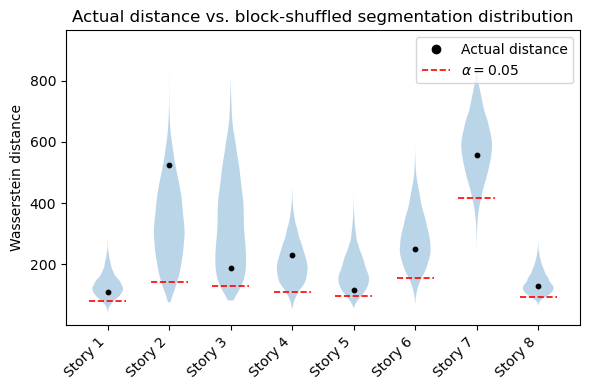

In [37]:
# Collect random samples in story order
data = [all_stories_dist_to_shuffled_smoothed[s] for s in stories]
actual = [all_stories_dist_smoothed[s] for s in stories]
chance_levels = [np.percentile(all_stories_dist_to_shuffled_smoothed[s], 5) 
                 for s in stories]

fig, ax = plt.subplots(figsize=(6, 4))

# Violin plot (vertical)
vp = ax.violinplot(data, showmeans=False, showextrema=False, showmedians=False)

# Plot actual values
ax.scatter(range(1, len(stories)+1), actual, zorder=3,s = 10,color = 'black')

# Chance levels (bottom 5%) in red dashed line
for i, cl in enumerate(chance_levels, start=1):
    ax.hlines(cl, i - 0.3, i + 0.3, colors='red', linestyles='--', linewidth=1.2)

legend_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markeredgecolor='black', markersize=6, label='Actual distance'),
    Line2D([0], [0], color='red', linestyle='--', linewidth=1.2, label=r'$\alpha = 0.05$'),
]
ax.legend(handles=legend_handles, loc='upper right', frameon=True)

# X-axis labels
ax.set_xticks(range(1, len(stories)+1))
ax.set_xticklabels(['Story '+str(story_to_idx_mapping[story]) for story in stories], rotation=45, ha='right')

ax.set_ylabel("Wasserstein distance")
ax.set_title("Actual distance vs. block-shuffled segmentation distribution")

plt.tight_layout()
fig.savefig(os.path.join(fig_save_dir,'wasserstein_distance_surprisal_vs_block_shuffled.svg'),transparent = True)
plt.show()


## punctuated 

In [7]:
def find_word_indices_in_tokenized_txt_punctuated(timing_df,tokenized_txt):
    def process_tokenized_word(tokenized_word):
        tokenized_word = tokenized_word.replace("âĢĻ", "’")
        tokenized_word = tokenized_word.replace("âĢĿ","\”")
        tokenized_word = tokenized_word.replace("âĢľ","\“")
        tokenized_word = tokenized_word.replace("’","\'")
        tokenized_word = tokenized_word.translate(str.maketrans('', '', model_initial_char+strip_chars))
        return tokenized_word
    '''
    input: original_txt (string, story transcript), tokenized_txt (list, tokenized by LM)
    output: list of lists, each sublist indicates the [start,end] (exclusive) indices or a word from the timing_df in the tokenized_txt. Handles punctuations'''
    start_idx_in_tokenized_txt = 0
    end_idx_in_tokenized_txt = 0
    curr_word = ''
    timing_df_text = timing_df['text']
    timing_df_text = ['' if isinstance(t,float) else t for t in timing_df_text]
    timing_df_text = [t[:-1] if t!='' and t[-1]==' ' else t for t in timing_df_text]
    word_indices_in_tokenized_txt = []
    strip_chars = string.punctuation + '-–“”'
    strip_chars = strip_chars.translate(str.maketrans('', '', '\'')) # don't strip ' (quote)
    for w in timing_df_text:
        while process_tokenized_word(tokenized_txt[start_idx_in_tokenized_txt]) in strip_chars: # a punctuation token
            start_idx_in_tokenized_txt +=1
            end_idx_in_tokenized_txt+=1
        while curr_word!=w and len(curr_word)<len(w):
            tokenized_word = tokenized_txt[end_idx_in_tokenized_txt]
            tokenized_word = process_tokenized_word(tokenized_word)
            curr_word+=tokenized_word
            end_idx_in_tokenized_txt+=1
        if curr_word.lower()==w.lower():
            word_indices_in_tokenized_txt.append([start_idx_in_tokenized_txt,end_idx_in_tokenized_txt])
            start_idx_in_tokenized_txt=end_idx_in_tokenized_txt
            curr_word = ''
        else:
            print('%s not found, currently processed %s'%(w,curr_word))
    return word_indices_in_tokenized_txt

In [8]:
punctuated_transcript_dir = '../../behavior_data/transcripts/punctuated'
timing_dir = '../../behavior_data/transcripts/timing'
all_stories_word_indices_in_tokenized_txt_punctuated = {}
for story in stories:
    with open(os.path.join(punctuated_transcript_dir,'%s_punctuated.txt'%story),'r') as f:
        punctuated_txt = f.read()
    #input_tokenized = tokenizer(punctuated_txt, return_tensors="pt").input_ids.to(device)
    input_tokenized_txt = tokenizer.tokenize(punctuated_txt)
    timing_df = pd.read_csv(os.path.join(timing_dir,'%s_timing.csv'%story))
    word_indices_in_tokenized_txt_punctuated = find_word_indices_in_tokenized_txt_punctuated(timing_df,input_tokenized_txt)
    all_stories_word_indices_in_tokenized_txt_punctuated[story]=np.array(word_indices_in_tokenized_txt_punctuated)


In [17]:
def get_segmentation_spans_punctuated(consensus_wordlist,timing_df,word_indices,tokenized_txt,initial_char):
    '''
    for each word humans segmented after, find its span in the punctuated tokenized_txt
    consensus_wordlist: output of segmentation_to_word_list (no punctuation, words with \n are followed by a human boundary)
    word_indices: all_stories_word_indices_in_tokenized_txt_punctuated[story], [start,end) of each timing_df word in tokenized_txt
    returns df with one row per boundary word:
        word_idx (row in timing_df), word, start_idx, word_end_idx (last token of the word itself),
        end_idx (last token including the punctuation right after the word), includes_punc
        both end indices are inclusive, like segmentation_indices_in_tokens
    '''
    timing_words = ['' if isinstance(t,float) else t for t in timing_df['text']]
    timing_words = [t[:-1] if t!='' and t[-1]==' ' else t for t in timing_words]
    # align consensus_wordlist to timing_df words. consensus txt sometimes has extra double spaces -> '' entries not in timing_df (e.g. souls)
    boundary_word_idx = []
    j = 0
    for i,w in enumerate(consensus_wordlist):
        w_clean = w.replace('\n','')
        if j<len(timing_words) and w_clean.lower()==timing_words[j].lower():
            if '\n' in w:
                boundary_word_idx.append(j)
            j+=1
        elif w_clean=='':
            assert '\n' not in w, 'boundary on an extra empty word at %d'%i
        else:
            raise ValueError('consensus word %d (%s) does not match timing word %d (%s)'%(i,w,j,timing_words[j] if j<len(timing_words) else None))
    assert j==len(timing_words), 'not all timing words matched'

    rows = []
    for j in boundary_word_idx:
        start,end = word_indices[j]
        next_start = word_indices[j+1][0] if j+1<len(word_indices) else len(tokenized_txt)
        # punctuation attached to the word has no leading space; tokens with initial_char belong to the next word (e.g. opening quotes)
        k = end
        while k<next_start and not tokenized_txt[k].startswith(initial_char):
            k+=1
        rows.append({'word_idx':j,'word':timing_words[j],'start_idx':start,'word_end_idx':end-1,
                     'end_idx':k-1,'includes_punc':k>end})
    return pd.DataFrame(rows)

In [23]:
def get_human_segment_bool_punc(segmentation_indices_in_tokens,original_ce):
    segmentation_indices_in_tokens = segmentation_indices_in_tokens[:-1] # get rid of the end of story
    human_segment_bool = torch.zeros(original_ce.shape)
    human_segment_bool[segmentation_indices_in_tokens] = 1
    human_segment_bool = human_segment_bool.numpy().astype(float)
    return human_segment_bool

In [24]:
punctuated_output_dir = os.path.join(save_dir,model_save_dir_name,'moth_stories_output_punctuated')
all_stories_kl_at_word_onsets_punctuated ={}
all_stories_segmentation_df_punctuated = {}
for story in stories:
    # these indices are wrt tokenized_txt which does not have BOS 
    # so to get P(t) for t (an index in word_indices_in_tokenized_txt_punctuated), you just need to index t into the softmaxed logits tensor
    # because logits[0] is BOS predicting the first token in tokenized_txt
    word_indices_in_tokenized_txt_punctuated = all_stories_word_indices_in_tokenized_txt_punctuated[story]
    punctuated_tokens = torch.load(os.path.join(punctuated_output_dir,story,'tokens.pkl'),map_location=torch.device('cpu'))
    punctuated_tokens = punctuated_tokens[0,1:].cpu().detach() # get rid of BOS
    with open(os.path.join(punctuated_output_dir,story,'tokenized_txt.pkl'),'rb') as f:
        punctuated_tokenized_txt = pickle.load(f)
    with open(os.path.join(punctuated_output_dir,story,'cross_entropy.pkl'),'rb') as f:
        punctuated_ce = pickle.load(f)

    consensus_path = os.path.join(segmentation_dir,story,'%s_consensus.txt'%story)
    with open(consensus_path,'r') as f:
        consensus_txt = f.read()
    consensus_txt = consensus_txt.split('\n')
    with open(os.path.join(original_transcript_dir,'%s.txt'%story),'r') as f:
        original_txt = f.read()
    consensus_wordlist = segmentation_to_word_list(consensus_txt)
    timing_df = pd.read_csv(os.path.join(timing_dir,'%s_timing.csv'%story))
    # humans segment after each of these words. start_idx/end_idx (inclusive) are wrt punctuated_tokenized_txt, end_idx includes punctuation right after the word
    segmentation_df_punctuated = get_segmentation_spans_punctuated(consensus_wordlist,timing_df,word_indices_in_tokenized_txt_punctuated,punctuated_tokenized_txt,model_initial_char)
    all_stories_segmentation_df_punctuated[story] = segmentation_df_punctuated

In [40]:
segmentation_df_punctuated.columns

Index(['word_idx', 'word', 'start_idx', 'word_end_idx', 'end_idx',
       'includes_punc'],
      dtype='object')

In [42]:
N = 5000
multiplier = 3.1
smooth_sd = 5
include_punc = True
all_stories_dist_smoothed_punctuated = {}
all_stories_dist_to_shuffled_smoothed_punctuated ={}
for story in stories:
    with open(os.path.join(punctuated_output_dir,story,'cross_entropy.pkl'),'rb') as f:
        punctuated_ce = pickle.load(f)
    segmentation_df_punctuated = all_stories_segmentation_df_punctuated[story]
    if not include_punc:
        end_indices = segmentation_df_punctuated['end_idx'].values
        end_indices_no_punc = []
        for i, (end_idx, is_punct) in enumerate(zip(end_indices, segmentation_df_punctuated['includes_punc'].values)):
            if not is_punct:
                end_indices_no_punc.append(end_idx)
            else:
                end_indices_no_punc.append(end_idx-1)
        end_indices_no_punc = np.array(end_indices_no_punc)
        human_segment_bool = get_human_segment_bool_punc(end_indices_no_punc,punctuated_ce)
    else:
        human_segment_bool = get_human_segment_bool_punc(segmentation_df_punctuated['end_idx'].values,punctuated_ce)
    surprisal_above_thresh = get_model_segment_bool(punctuated_ce,multiplier)

    human_segment_bool_smoothed = gaussian_filter1d(human_segment_bool,smooth_sd)
    surprisal_segment_smoothed = gaussian_filter1d(surprisal_above_thresh,smooth_sd)
    indices = np.arange(len(human_segment_bool))
    dist_discrete = wasserstein_distance(u_values = indices, v_values = indices,u_weights = human_segment_bool,v_weights = surprisal_above_thresh)
    dist_smoothed = wasserstein_distance(u_values = indices, v_values = indices,u_weights = human_segment_bool_smoothed,v_weights = surprisal_segment_smoothed)
    dist_to_shuffled_discrete,dist_to_shuffled_smoothed = shuffled_boundaries(surprisal_above_thresh,human_segment_bool,human_segment_bool_smoothed,smooth_sd,np.sum(surprisal_above_thresh>0),N)

    print(story)
    print('Num human segmentation: %d, num surprisal segmentation: %d'%(np.sum(human_segment_bool>0),np.sum(surprisal_above_thresh>0)))
    print('discrete, % block shuffled boundary distance > actual:',np.sum(dist_to_shuffled_discrete>dist_discrete)/N)
    print('smoothed, % block shuffled boundary distance > actual:',np.sum(dist_to_shuffled_smoothed>dist_smoothed)/N)

    print()
    # plt.figure(figsize = (10,1))
    # #plt.plot(surprisal_above_thresh)
    # plt.plot(surprisal_segment_smoothed,label = 'surprisal')
    # plt.plot(human_segment_bool_smoothed,label = 'human')
    # #plt.plot(human_segment_bool)
    # plt.legend()
    # plt.title(story)
    all_stories_dist_smoothed_punctuated[story] = dist_smoothed
    all_stories_dist_to_shuffled_smoothed_punctuated[story] = dist_to_shuffled_smoothed
    #print(torch.sum(original_ce>thresh),len(segmentation_indices_in_tokens))

pieman
Num human segmentation: 11, num surprisal segmentation: 16
discrete, % block shuffled boundary distance > actual: 0.709
smoothed, % block shuffled boundary distance > actual: 0.7082

alternateithicatom
Num human segmentation: 20, num surprisal segmentation: 35
discrete, % block shuffled boundary distance > actual: 0.392
smoothed, % block shuffled boundary distance > actual: 0.3914

odetostepfather
Num human segmentation: 27, num surprisal segmentation: 39
discrete, % block shuffled boundary distance > actual: 0.7416
smoothed, % block shuffled boundary distance > actual: 0.742

souls
Num human segmentation: 17, num surprisal segmentation: 36
discrete, % block shuffled boundary distance > actual: 0.7526
smoothed, % block shuffled boundary distance > actual: 0.7532

legacy
Num human segmentation: 20, num surprisal segmentation: 35
discrete, % block shuffled boundary distance > actual: 0.6098
smoothed, % block shuffled boundary distance > actual: 0.611

wheretheressmoke
Num human se

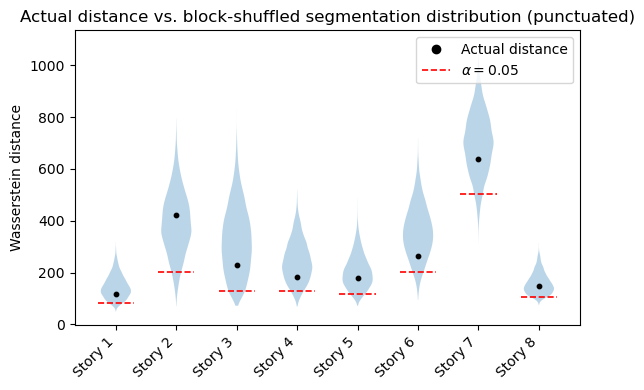

In [43]:
# Collect random samples in story order
data = [all_stories_dist_to_shuffled_smoothed_punctuated[s] for s in stories]
actual = [all_stories_dist_smoothed_punctuated[s] for s in stories]
chance_levels = [np.percentile(all_stories_dist_to_shuffled_smoothed_punctuated[s], 5) 
                 for s in stories]

fig, ax = plt.subplots(figsize=(6, 4))

# Violin plot (vertical)
vp = ax.violinplot(data, showmeans=False, showextrema=False, showmedians=False)

# Plot actual values
ax.scatter(range(1, len(stories)+1), actual, zorder=3,s = 10,color = 'black')

# Chance levels (bottom 5%) in red dashed line
for i, cl in enumerate(chance_levels, start=1):
    ax.hlines(cl, i - 0.3, i + 0.3, colors='red', linestyles='--', linewidth=1.2)

legend_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markeredgecolor='black', markersize=6, label='Actual distance'),
    Line2D([0], [0], color='red', linestyle='--', linewidth=1.2, label=r'$\alpha = 0.05$'),
]
ax.legend(handles=legend_handles, loc='upper right', frameon=True)

# X-axis labels
ax.set_xticks(range(1, len(stories)+1))
ax.set_xticklabels(['Story '+str(story_to_idx_mapping[story]) for story in stories], rotation=45, ha='right')

ax.set_ylabel("Wasserstein distance")
ax.set_title("Actual distance vs. block-shuffled segmentation distribution (punctuated)")

plt.tight_layout()
fig.savefig(os.path.join(fig_save_dir,'wasserstein_distance_surprisal_vs_block_shuffled_punctuated.svg'),transparent = True)
plt.show()
